[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_App_NB12_parameter_inference.ipynb)

# Appendix · Notebook 12 — Which parameters explain the data? Sweeps, degeneracy and simulation-based inference

**Goal.** Every model in this course has parameters (coupling $G$, excitability $\eta$, noise $\sigma$…). Given data, which
values should we use? This is the **inverse problem**. Simulating a model is easy (parameters → data); going back is hard,
because **different parameters can produce the same data** (*degeneracy*).

We use the simplest possible "brain region": the noise-driven oscillator of NB07 (a damped oscillation kicked by noise),
with two parameters: the distance to the bifurcation $\mu$ (how fast fluctuations decay) and the noise $\sigma$.
The same ideas apply to any model, from single neurons to whole brains.

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import normal_forms as nf
rng = np.random.default_rng(0)

def simulate(mu, sigma, seed=0, T=300.0):
    t, z = nf.hopf(mu, omega=np.pi, sigma=sigma, T=T, dt=1e-2, z0=0j, seed=seed)
    return z.real[t > 20][::5]                     # sampled every 0.05

from scipy.signal import hilbert

def summaries(x):
    tau, _ = nf.autocorr_time(hilbert(x), 0.05)   # decay of the envelope of the autocorrelation (not the oscillation)
    return np.array([x.var(), tau])               # variance and correlation time

## 1. The "data"

Pretend this is a recording from a brain region, and that the true parameters (unknown to us) are $\mu=-0.2$, $\sigma=0.05$.

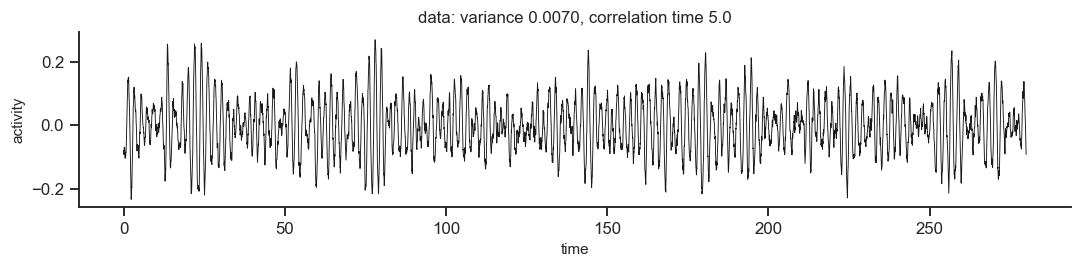

In [2]:
mu_true, sigma_true = -0.2, 0.05
data = simulate(mu_true, sigma_true, seed=123)
s_data = summaries(data)
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.plot(np.arange(len(data)) * 0.05, data, "k", lw=0.6); ax.set(xlabel="time", ylabel="activity", title=f"data: variance {s_data[0]:.4f}, correlation time {s_data[1]:.1f}")
plt.tight_layout()

## 2. Parameter sweep: degeneracy

Simulate the model on a grid of $(\mu,\sigma)$ and measure how far each simulation is from the data, first using **only the
variance** of the signal.

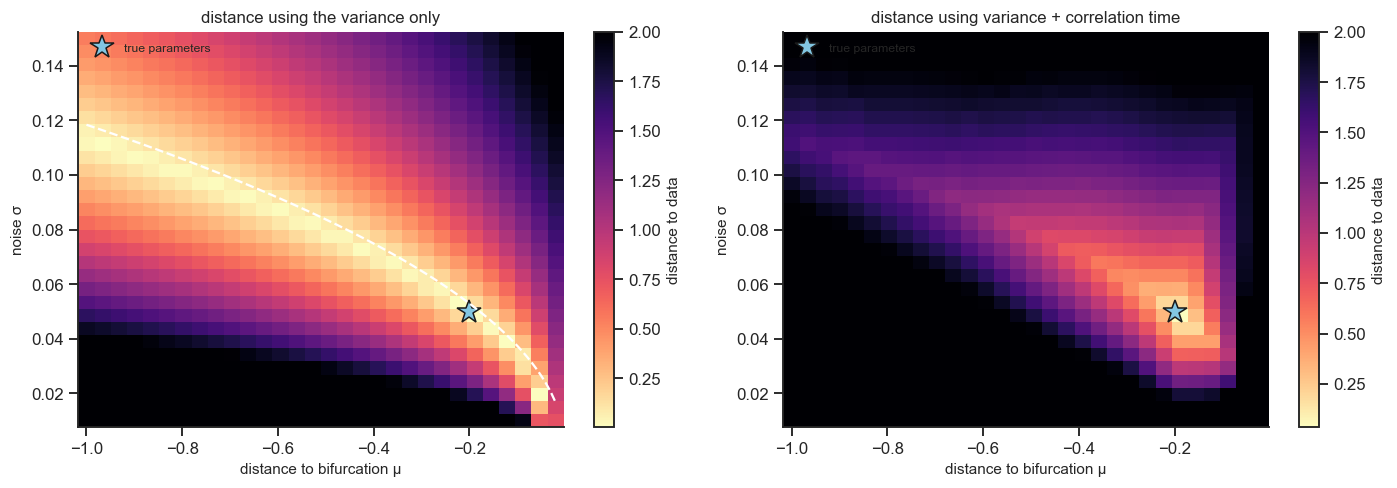

In [3]:
mus = np.linspace(-1.0, -0.02, 30); sigmas = np.linspace(0.01, 0.15, 30)
S_grid = np.array([[summaries(simulate(m, s, seed=1)) for m in mus] for s in sigmas])     # (sigma, mu, 2)
d_var = np.abs(np.log(S_grid[..., 0] / s_data[0]))
d_both = d_var + np.abs(np.log(S_grid[..., 1] / s_data[1]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a_, d, title in [(ax[0], d_var, "distance using the variance only"), (ax[1], d_both, "distance using variance + correlation time")]:
    im = a_.pcolormesh(mus, sigmas, d, cmap="magma_r", vmax=2, shading="auto"); plt.colorbar(im, ax=a_, label="distance to data")
    a_.plot(mu_true, sigma_true, "c*", ms=16, mec="k", label="true parameters")
    a_.set(xlabel="distance to bifurcation μ", ylabel="noise σ", title=title); a_.legend(fontsize=8, loc="upper left")
mm = np.linspace(-1, -0.02, 100)
ax[0].plot(mm, np.sqrt(2 * np.abs(mm) * s_data[0]), "w--", lw=1.5)
plt.tight_layout()

* **Left.** With only the variance, a whole **ridge** of parameters fits the data equally well (dashed line: theory,
  variance $=\sigma^2/2|\mu|$). A region far from its bifurcation with strong noise looks the same as a region close to it
  with weak noise. This is **degeneracy**: the data do not determine the parameters.
* **Right.** Adding a second feature, the correlation time ($=1/|\mu|$), breaks the degeneracy: only one region of
  parameter space fits.

Degeneracy is not a technical nuisance, it is biology: very different combinations of ion-channel densities produce the same
neuronal activity (Prinz, Bucher & Marder 2004; Marder & Goaillard 2006). The lesson: choose features of the data that are
sensitive to the parameters you care about, and report *all* the parameters that fit, not just the best one.

## 3. Simulation-based inference (SBI), in its simplest form

Grids become impossible with many parameters. SBI replaces the grid with random simulations and returns a **posterior
distribution**: how plausible each parameter value is given the data.

The simplest version (*rejection sampling*, or approximate Bayesian computation):
1. draw parameters at random from a **prior** (the plausible range);
2. simulate and compute the features;
3. keep the parameters whose features are closest to the data's.

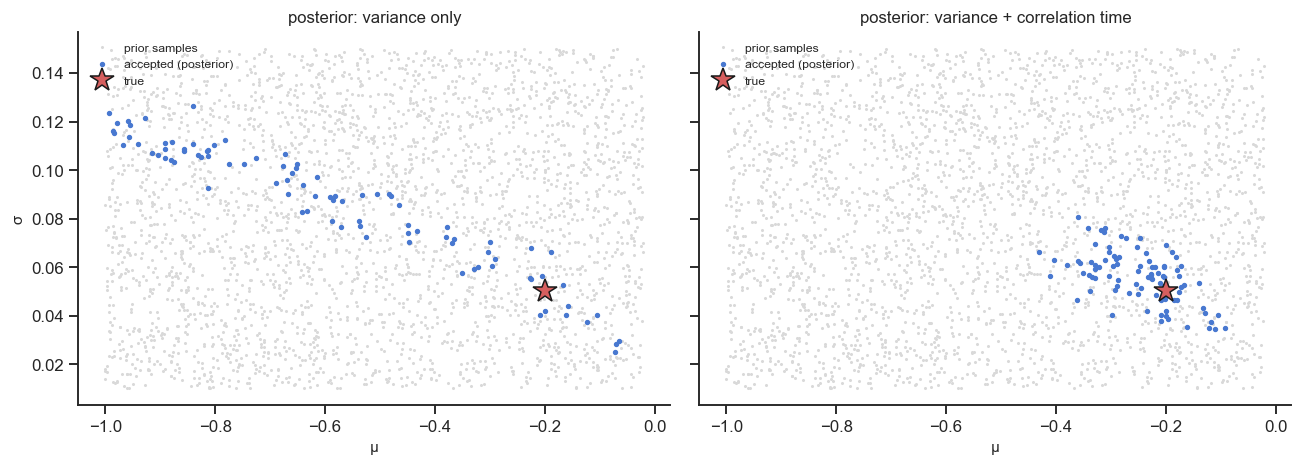

In [4]:
n_sim = 3000
prior_mu = rng.uniform(-1.0, -0.02, n_sim); prior_sigma = rng.uniform(0.01, 0.15, n_sim)
feats = np.array([summaries(simulate(m, s, seed=k, T=150.0)) for k, (m, s) in enumerate(zip(prior_mu, prior_sigma))])
dist_var = np.abs(np.log(feats[:, 0] / s_data[0]))
dist_both = dist_var + np.abs(np.log(feats[:, 1] / s_data[1]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True, sharey=True)
for a_, d, title in [(ax[0], dist_var, "posterior: variance only"), (ax[1], dist_both, "posterior: variance + correlation time")]:
    keep = d < np.quantile(d, 0.03)                  # keep the closest 3% of simulations
    a_.plot(prior_mu, prior_sigma, ".", c="0.85", ms=2, label="prior samples")
    a_.plot(prior_mu[keep], prior_sigma[keep], ".", c="C0", ms=5, label="accepted (posterior)")
    a_.plot(mu_true, sigma_true, "r*", ms=16, mec="k", label="true")
    a_.set(xlabel="μ", title=title); a_.legend(fontsize=8)
ax[0].set_ylabel("σ")
plt.tight_layout()

The accepted simulations form the posterior: an elongated cloud along the degenerate ridge with one feature, a compact cloud
around the truth with two. The correlation between parameters in the posterior *is* the degeneracy, made visible.

**Modern SBI** replaces "keep the closest" with a neural network that learns the posterior from the simulations
(*neural posterior estimation*): far fewer simulations, many parameters, and features that can themselves be learned. The
`sbi` toolbox (Python) implements it; for whole-brain models, the same approach estimates coupling and regional excitabilities
from fMRI (e.g. Hashemi et al. 2023; Rabuffo et al. 2025, *PNAS*, used it to infer lesion-induced changes in excitability).

## Take-home
* The inverse problem (data → parameters) is harder than simulation, because of **degeneracy**.
* A parameter sweep shows it directly; the choice of data features decides what can be identified.
* SBI turns simulations into a posterior distribution; correlated parameters in the posterior reveal degeneracy.

### Homework
*To do at home, after the class. These exercises take the questions of the notebook further.*
1. Repeat the inference with less data (`T=50`). How does the posterior change?
2. Add a third feature (the dominant frequency of the spectrum). Can you also infer $\omega$ if you let it vary?
3. Use the G sweep of NB09 (`data/cache/nb09_sweep.npz`): treat the mean FC of the mouse data as the observation and find which
   values of G are compatible with it. Is G identifiable from mean FC alone?

### References
* Cranmer K, Brehmer J, Louppe G (2020). The frontier of simulation-based inference. *PNAS* 117:30055.
* Gonçalves PJ et al. (2020). Training deep neural density estimators to identify mechanistic models of neural dynamics. *eLife* 9:e56261.
* Tejero-Cantero A et al. (2020). sbi: a toolkit for simulation-based inference. *J Open Source Softw* 5:2505.
* Hashemi M et al. (2023). Amortized Bayesian inference on generative dynamical network models of epilepsy using deep neural density estimators. *Neural Netw* 163:178.
* Prinz AA, Bucher D, Marder E (2004). Similar network activity from disparate circuit parameters. *Nat Neurosci* 7:1345.
* Marder E, Goaillard J-M (2006). Variability, compensation and homeostasis in neuron and network function. *Nat Rev Neurosci* 7:563.